# LAB ASSIGNMENT 4: Supervised Learning: Classification

**SET A – Q1**
Decision Tree Classifier using Diabetes Dataset

**Aim:**
Write a Python program to build a Decision Tree Classifier using the Scikit-learn package for the Pima Indians Diabetes Dataset.

**Step 1:** Download the dataset from kaggle and upload it here/
- go to https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv and download the zip -> extract it -> upload it to colab (choose file)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving pima-indians-diabetes.csv to pima-indians-diabetes (1).csv


**Step 2:** Import the required libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

**Step 4:** Load the dataset

In [ ]:
data = pd.read_csv("pima-indians-diabetes.csv")

print("First five records:")
print(data.head())

First five records:
   6  148  72  35    0  33.6  0.627  50  1
0  1   85  66  29    0  26.6  0.351  31  0
1  8  183  64   0    0  23.3  0.672  32  1
2  1   89  66  23   94  28.1  0.167  21  0
3  0  137  40  35  168  43.1  2.288  33  1
4  5  116  74   0    0  25.6  0.201  30  0


**Check your dataset columns**

In [ ]:
print(data.columns.tolist())

# Remove extra spaces from the column names
data.columns = data.columns.str.strip()
print(data.columns.tolist())



['6', '148', '72', '35', '0', '33.6', '0.627', '50', '1']
['6', '148', '72', '35', '0', '33.6', '0.627', '50', '1']


This means Pandas is treating the first row of your dataset as column headings, instead of actual data.

Your CSV file does not have a header row. Let's fix it.


**Step 1:** Load the CSV correctly

In [ ]:
import pandas as pd

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

data = pd.read_csv(
    "pima-indians-diabetes.csv",
    header=None,
    names=columns
)

print(data.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


**Step 2:** Separate Input and Output

In [ ]:
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Target values:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


Here,

80% data is used for training.


20% data is used for testing.

**Step 7:** Create the Decision Tree Classifier

In [ ]:
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

**Step 8:** Train the model

In [ ]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


**Step 9:** Predict the output

In [ ]:
y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred)

Predicted values:
[0 0 0 0 0 0 0 1 1 0 0 0 1 1 0 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 1 1 1 1 1
 1 0 1 0 0 1 1 0 1 1 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 1 1 0 0 0
 0 1 0 0 0 0 0 0 0 1 1 1 0 1 1 0 0 0 0 0 1 0 1 0 1 0 1 0 1 0 1 0 0 1 0 1 0
 1 0 1 1 1 1 0 0 0 0 0 0 0 0 1 1 0 1 1 1 1 0 0 1 1 0 1 1 0 0 0 0 0 0 0 0 0
 0 1 0 1 1 0]


**Step 10:** Calculate Accuracy

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 72.07792207792207 %


**Step 11:** Display Confusion Matrix

In [ ]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[76 23]
 [20 35]]


**Step 12:** Display classification report

In [ ]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.77      0.78        99
           1       0.60      0.64      0.62        55

    accuracy                           0.72       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.72      0.72      0.72       154



**Step 13:** Visualize the Decision Tree

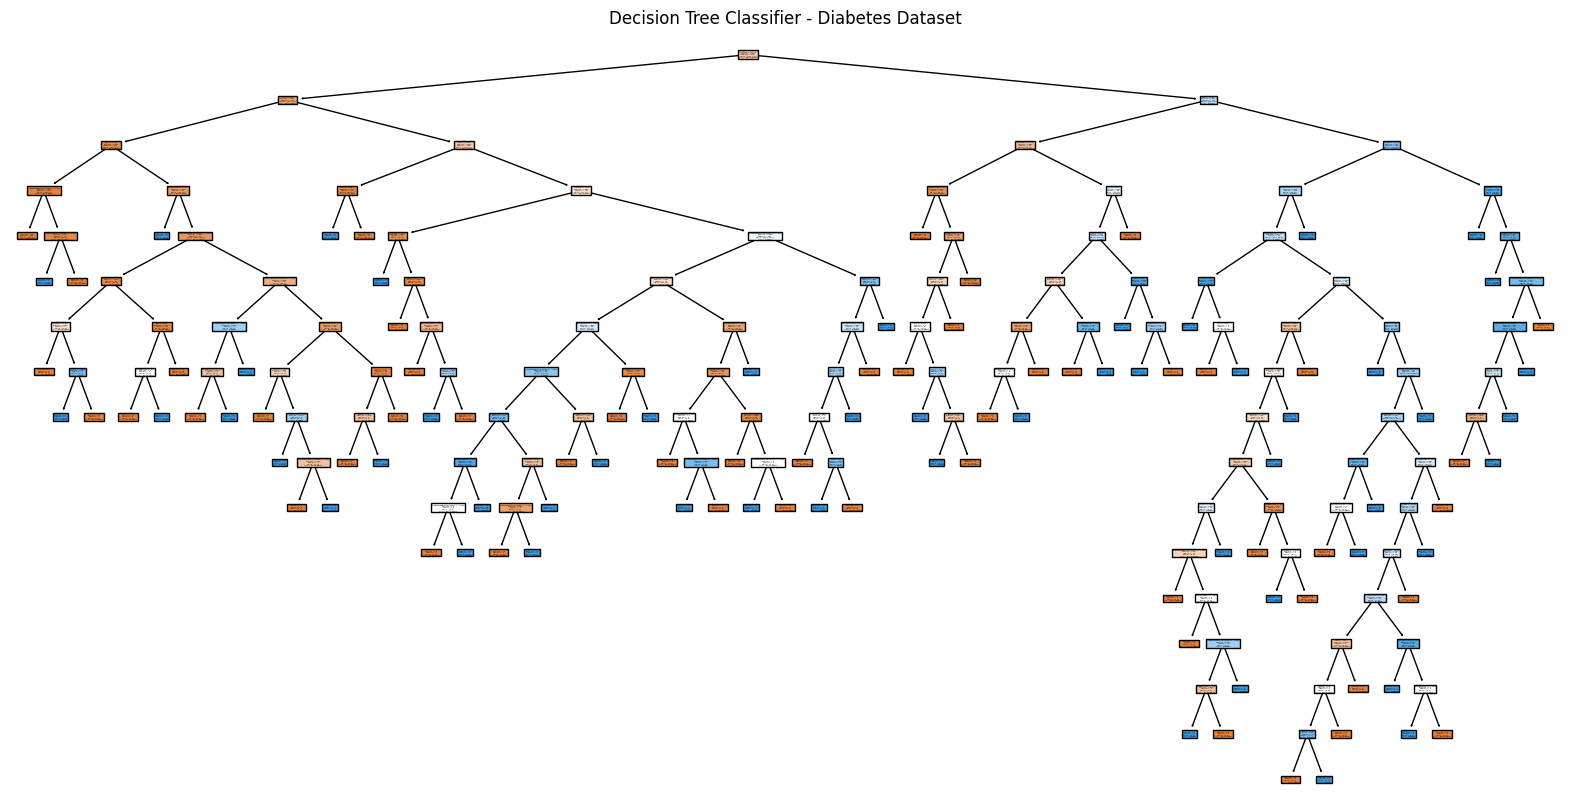

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Non-Diabetic", "Diabetic"],
    filled=True
)

plt.title("Decision Tree Classifier - Diabetes Dataset")
plt.show()

**Step 14:** Result

In [ ]:
print("Result: Decision Tree Classifier executed successfully.")

Result: Decision Tree Classifier executed successfully.


**SET A**

**Q2:** Decision Tree Classifier using Shows Dataset


**Aim:** Write a Python program to build a Decision Tree Classifier for shows.csv and predict whether a 40-year-old American comedian with 10 years of experience and a comedy ranking of 7 should go to the show.

**Step 1:** Import the required libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier


# Step 2:  Create the shows dataset
data = {
    'Age': [36, 42, 23, 52, 43, 44, 66, 35, 52, 35, 24, 18, 45],

    'Experience': [10, 12, 4, 4, 21, 14, 3, 14, 13, 5, 3, 3, 9],

    'Rank': [9, 4, 6, 4, 8, 5, 7, 9, 7, 9, 5, 7, 9],

    'Nationality': ['UK', 'USA', 'N', 'USA', 'USA', 'UK',
                    'N', 'UK', 'N', 'N', 'USA', 'UK', 'UK'],

    'Go': ['NO', 'NO', 'NO', 'NO', 'YES', 'NO', 'YES',
           'YES', 'YES', 'YES', 'NO', 'YES', 'YES']
}

df = pd.DataFrame(data)

df.to_csv("shows.csv", index=False)

print("Shows.csv file created successfully!")
print(df)

Shows.csv file created successfully!
    Age  Experience  Rank Nationality   Go
0    36          10     9          UK   NO
1    42          12     4         USA   NO
2    23           4     6           N   NO
3    52           4     4         USA   NO
4    43          21     8         USA  YES
5    44          14     5          UK   NO
6    66           3     7           N  YES
7    35          14     9          UK  YES
8    52          13     7           N  YES
9    35           5     9           N  YES
10   24           3     5         USA   NO
11   18           3     7          UK  YES
12   45           9     9          UK  YES


**Step 3:** Read the CSV file

In [ ]:
df = pd.read_csv("shows.csv")

print("Original Dataset:")
print(df)

Original Dataset:
    Age  Experience  Rank Nationality   Go
0    36          10     9          UK   NO
1    42          12     4         USA   NO
2    23           4     6           N   NO
3    52           4     4         USA   NO
4    43          21     8         USA  YES
5    44          14     5          UK   NO
6    66           3     7           N  YES
7    35          14     9          UK  YES
8    52          13     7           N  YES
9    35           5     9           N  YES
10   24           3     5         USA   NO
11   18           3     7          UK  YES
12   45           9     9          UK  YES


**Step 4:** Convert categorical values into numerical values.


Machine learning algorithms require numerical input, so we convert the categorical values.

In [ ]:
d = {'UK': 0, 'USA': 1, 'N': 2}

df['Nationality'] = df['Nationality'].map(d)

d = {'YES': 1, 'NO': 0}

df['Go'] = df['Go'].map(d)

print("Converted Dataset:")
print(df)

Converted Dataset:
    Age  Experience  Rank  Nationality  Go
0    36          10     9            0   0
1    42          12     4            1   0
2    23           4     6            2   0
3    52           4     4            1   0
4    43          21     8            1   1
5    44          14     5            0   0
6    66           3     7            2   1
7    35          14     9            0   1
8    52          13     7            2   1
9    35           5     9            2   1
10   24           3     5            1   0
11   18           3     7            0   1
12   45           9     9            0   1


**Step 5:** Separate features and target

In [ ]:
features = ['Age', 'Experience', 'Rank', 'Nationality']

X = df[features]
y = df['Go']

**Step 6:** Create the Decision Tree Classifier

In [ ]:
dtree = DecisionTreeClassifier()

**Step 7:** Train the model

In [ ]:
dtree = dtree.fit(X, y)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


**Step 8:** Predict the class label
Given information:
- Age = 40
- Experience = 10 years
- Rank = 7
- Nationality = USA (1)

In [ ]:
prediction = dtree.predict(
    pd.DataFrame([[40, 10, 7, 1]], columns=features)
)

print("Prediction:", prediction)

if prediction[0] == 1:
    print("The result is YES - GO to the comedy show.")
else:
    print("The result is NO - DO NOT GO to the comedy show.")

Prediction: [0]
The result is NO - DO NOT GO to the comedy show.


**Step 9:** Display the Decision Tree

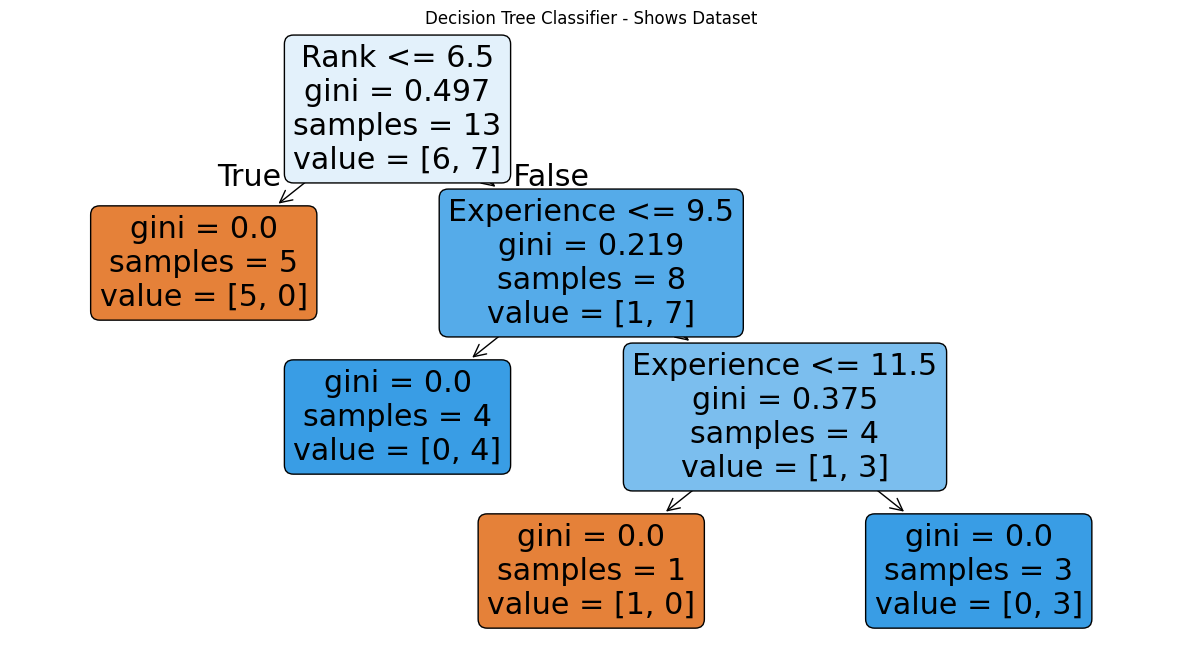

In [ ]:
plt.figure(figsize=(15, 8))

tree.plot_tree(
    dtree,
    feature_names=features,
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classifier - Shows Dataset")
plt.show()

**Step 10:** Result

In [ ]:
print("Result: Decision Tree Classifier executed successfully.")

Result: Decision Tree Classifier executed successfully.


**SET B:** Q1


**Naive Bayes Classification – Play Sports Prediction**


**Aim**
Write a Python program using the Naive Bayes algorithm to predict whether a person should play sports based on weather and temperature.

*Given tuple:*

[0: Overcast, 2: Mild]


**Step 1:** Import the required libraries

In [ ]:
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import CategoricalNB

**Step 2:** Create the dataset

In [ ]:
weather = [
    'Sunny', 'Sunny', 'Overcast', 'Rainy',
    'Rainy', 'Rainy', 'Overcast', 'Sunny',
    'Sunny', 'Rainy', 'Sunny', 'Overcast',
    'Overcast', 'Rainy'
]

temp = [
    'Hot', 'Hot', 'Hot', 'Mild',
    'Cool', 'Cool', 'Cool', 'Mild',
    'Cool', 'Mild', 'Mild', 'Mild',
    'Hot', 'Mild'
]

play = [
    'No', 'No', 'Yes', 'Yes',
    'Yes', 'No', 'Yes', 'No',
    'Yes', 'Yes', 'Yes', 'Yes',
    'Yes', 'No'
]

**Step 3:** Create DataFrame

In [ ]:
data = pd.DataFrame({
    'Weather': weather,
    'Temperature': temp,
    'Play': play
})

print("Original Dataset:")
print(data)

Original Dataset:
     Weather Temperature Play
0      Sunny         Hot   No
1      Sunny         Hot   No
2   Overcast         Hot  Yes
3      Rainy        Mild  Yes
4      Rainy        Cool  Yes
5      Rainy        Cool   No
6   Overcast        Cool  Yes
7      Sunny        Mild   No
8      Sunny        Cool  Yes
9      Rainy        Mild  Yes
10     Sunny        Mild  Yes
11  Overcast        Mild  Yes
12  Overcast         Hot  Yes
13     Rainy        Mild   No


**Step 4:** Convert categorical values into numerical values

In [ ]:
le_weather = LabelEncoder()
le_temp = LabelEncoder()
le_play = LabelEncoder()

data['Weather'] = le_weather.fit_transform(data['Weather'])

data['Temperature'] = le_temp.fit_transform(data['Temperature'])

data['Play'] = le_play.fit_transform(data['Play'])

print("Encoded Dataset:")
print(data)

Encoded Dataset:
    Weather  Temperature  Play
0         2            1     0
1         2            1     0
2         0            1     1
3         1            2     1
4         1            0     1
5         1            0     0
6         0            0     1
7         2            2     0
8         2            0     1
9         1            2     1
10        2            2     1
11        0            2     1
12        0            1     1
13        1            2     0


**Step 5:** Separate input and output variables

In [ ]:
X = data[['Weather', 'Temperature']]
y = data['Play']

**Step 6:** Create the Naive Bayes model

In [ ]:
model = CategoricalNB()

**Step 7:** Train the model

In [ ]:
model.fit(X, y)
print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


**Step 8:** Predict the given tuple

In [ ]:
prediction = model.predict(
    pd.DataFrame([[0, 2]], columns=['Weather', 'Temperature'])
)


#Here: 0 represents Overcast. And 2 represents Mild.

**Step 9:** Display the prediction

In [ ]:
result = le_play.inverse_transform(prediction)

print("Given Tuple: [0: Overcast, 2: Mild]")

print("Predicted Class:", result[0])

if result[0] == 'Yes':
    print("Decision: Play Sports")
else:
    print("Decision: Do Not Play Sports")

Given Tuple: [0: Overcast, 2: Mild]
Predicted Class: Yes
Decision: Play Sports


**Step 10:** Result

In [ ]:
print("Result: Naive Bayes Classification executed successfully.")

Result: Naive Bayes Classification executed successfully.


SET C – Q1
Support Vector Machine (SVM) – Cancer Dataset


**Aim** - Write a Python program to build an SVM model using the Breast Cancer dataset available in Scikit-learn. Check the accuracy, precision and recall of the model.

**Step 1** – Import the required libraries
Create a new code cell:

In [ ]:
from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

**Step 2** – Load the Cancer Dataset

In [ ]:
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

print("Dataset Loaded Successfully")

print("Total Records:", X.shape[0])

print("Total Features:", X.shape[1])

Dataset Loaded Successfully
Total Records: 569
Total Features: 30


**Step 3** – Split the dataset into training and testing

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


Here:

- 80% data is used for training.
- 20% data is used for testing.

**Step 4** – Apply Feature Scaling

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

**Step 5** – Create SVM model

In [ ]:
model = SVC(kernel='linear')

# Here, linear is the kernel used to create the SVM model.

**Step 6** – Train the model

In [ ]:
model.fit(X_train, y_train)

print("SVM Model Trained Successfully")

SVM Model Trained Successfully


**Step 7** – Predict the output

In [ ]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred)

Predicted Values:
[1 0 0 1 1 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1 0 0 1 1 0 0 1 1 1 0 0 1 1 0 0 1 0
 1 1 1 1 1 1 0 1 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 1 1 0
 1 0 0]


**Step 8** – Calculate Accuracy

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 95.6140350877193 %


**Step 9** – Calculate Precision

In [ ]:
precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.9714285714285714


**Step 10** – Calculate Recall

In [ ]:
recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.9577464788732394


**Step 11** – Display Confusion Matrix

In [ ]:
print("Confusion Matrix:")

print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[41  2]
 [ 3 68]]


**Step 12** – Display Classification Report

In [ ]:
print("Classification Report:")

print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94        43
           1       0.97      0.96      0.96        71

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



**Step 13** – Result

In [ ]:
print("Result: SVM Classification executed successfully.")

Result: SVM Classification executed successfully.


| Question | Answer |
|---|---|
| What is classification? | Classification is a supervised machine learning technique used to predict categorical labels. |
| What is Decision Tree? | It is a tree-structured algorithm used for making decisions based on conditions. |
| What is Naive Bayes? | It is a classification algorithm based on Bayes' theorem. |
| What is SVM? | Support Vector Machine is a supervised learning algorithm used mainly for classification. |
| What is training data? | Data used to train the machine learning model. |
| What is testing data? | Data used to evaluate the trained model. |
| What is accuracy? | The percentage of correct predictions. |
| What is precision? | The proportion of correctly predicted positive cases among all predicted positive cases. |
| What is recall? | The proportion of actual positive cases correctly identified by the model. |
| What is confusion matrix? | A table that compares actual and predicted classification results. |
| What is feature scaling? | A technique used to bring numerical features to a similar scale. |
| What is Scikit-learn? | A Python library used for machine learning. |